<a href="https://colab.research.google.com/github/fauzia-annisa/Product-Defect-Detection-Dinov2/blob/main/Product_Defect_Detection_Dinov2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1: Install and download the dataset (MVTec AD, “bottle”)

In [6]:
!pip -q install fastapi uvicorn python-multipart scikit-learn scipy pillow requests huggingface_hub

from huggingface_hub import snapshot_download
snapshot_download(repo_id="aristrops/mvtec-concepts", repo_type="dataset",
                  local_dir="mvtec", allow_patterns=["bottle/*"])

!ls mvtec/bottle
!ls mvtec/bottle/train/good | head -3
!ls mvtec/bottle/train/good | wc -l
!ls mvtec/bottle/test
!ls mvtec/bottle/ground_truth

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 421 files:   0%|          | 0/421 [00:00<?, ?it/s]

concepts  generated_anomalies  ground_truth  test  train
000.png
001.png
002.png
209
broken_large  broken_small  contamination  good
broken_large  broken_small  contamination


Cell 2: Model, memory bank, scoring

In [7]:
import glob, os, numpy as np, torch, torch.nn.functional as F
from PIL import Image
import torchvision.transforms as T
from scipy.ndimage import gaussian_filter
from sklearn.metrics import roc_auc_score

device = "cuda" if torch.cuda.is_available() else "cpu"
SIZE = 336            # multiple of 14. Use 448 for tiny defects (slower)
G = SIZE // 14        # patch grid
CAT = "mvtec/bottle"

model = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14").to(device).eval()

tf = T.Compose([T.Resize((SIZE, SIZE)), T.ToTensor(),
                T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

@torch.no_grad()
def patch_feats(img):                      # PIL -> (G*G, 384)
    x = tf(img.convert("RGB")).unsqueeze(0).to(device)
    return model.forward_features(x)["x_norm_patchtokens"][0]

# ---- Build memory bank from NORMAL images only ----
train = sorted(glob.glob(f"{CAT}/train/good/*.png"))
calib, fit = train[:20], train[20:]        # hold out 20 normals to set threshold

bank = torch.cat([patch_feats(Image.open(p)) for p in fit])
if len(bank) > 60000:                      # random subsample to keep it fast
    bank = bank[torch.randperm(len(bank))[:60000]]
print("Memory bank:", bank.shape)

@torch.no_grad()
def score(img):
    f = patch_feats(img)
    d = torch.cdist(f, bank).min(dim=1).values          # nearest-normal distance
    amap = d.reshape(1,1,G,G)
    amap = F.interpolate(amap, size=img.size[::-1], mode="bilinear", align_corners=False)[0,0]
    amap = gaussian_filter(amap.cpu().numpy(), sigma=4)
    return float(amap.max()), amap

# ---- Threshold from held-out normals ----
cal_scores = [score(Image.open(p))[0] for p in calib]
thr = float(np.max(cal_scores))
print("Threshold:", thr)

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Memory bank: torch.Size([60000, 384])
Threshold: 26.42687225341797


In [8]:
import glob, os
for d in ["broken_large", "broken_small", "contamination"]:
    imgs = sorted(glob.glob(f"{CAT}/test/{d}/*.png"))[:2]
    for p in imgs:
        mp = f"{CAT}/ground_truth/{d}/{os.path.basename(p).replace('.png','_mask.png')}"
        print(d, os.path.basename(p), "-> mask exists:", os.path.exists(mp))

broken_large 000.png -> mask exists: True
broken_large 001.png -> mask exists: True
broken_small 000.png -> mask exists: True
broken_small 001.png -> mask exists: True
contamination 000.png -> mask exists: True
contamination 001.png -> mask exists: True


Cell 3: Evaluate (image AUROC and pixel AUROC)

In [9]:
y_true, y_score, px_true, px_score = [], [], [], []
for d in sorted(os.listdir(f"{CAT}/test")):
    for p in sorted(glob.glob(f"{CAT}/test/{d}/*.png")):
        img = Image.open(p)
        s, amap = score(img)
        y_true.append(0 if d == "good" else 1); y_score.append(s)
        if d == "good":
            m = np.zeros(amap.shape, dtype=np.uint8)
        else:
            mp = f"{CAT}/ground_truth/{d}/{os.path.basename(p).replace('.png','_mask.png')}"
            m = (np.array(Image.open(mp).convert("L").resize(img.size)) > 0).astype(np.uint8)
        px_true.append(m.ravel()[::7]); px_score.append(amap.ravel()[::7])  # subsample for speed

print("Image AUROC:", round(roc_auc_score(y_true, y_score), 4))
print("Pixel AUROC:", round(roc_auc_score(np.concatenate(px_true), np.concatenate(px_score)), 4))

Image AUROC: 1.0
Pixel AUROC: 0.9898


Cell 4: Visualize heatmaps (put these in your portfolio)

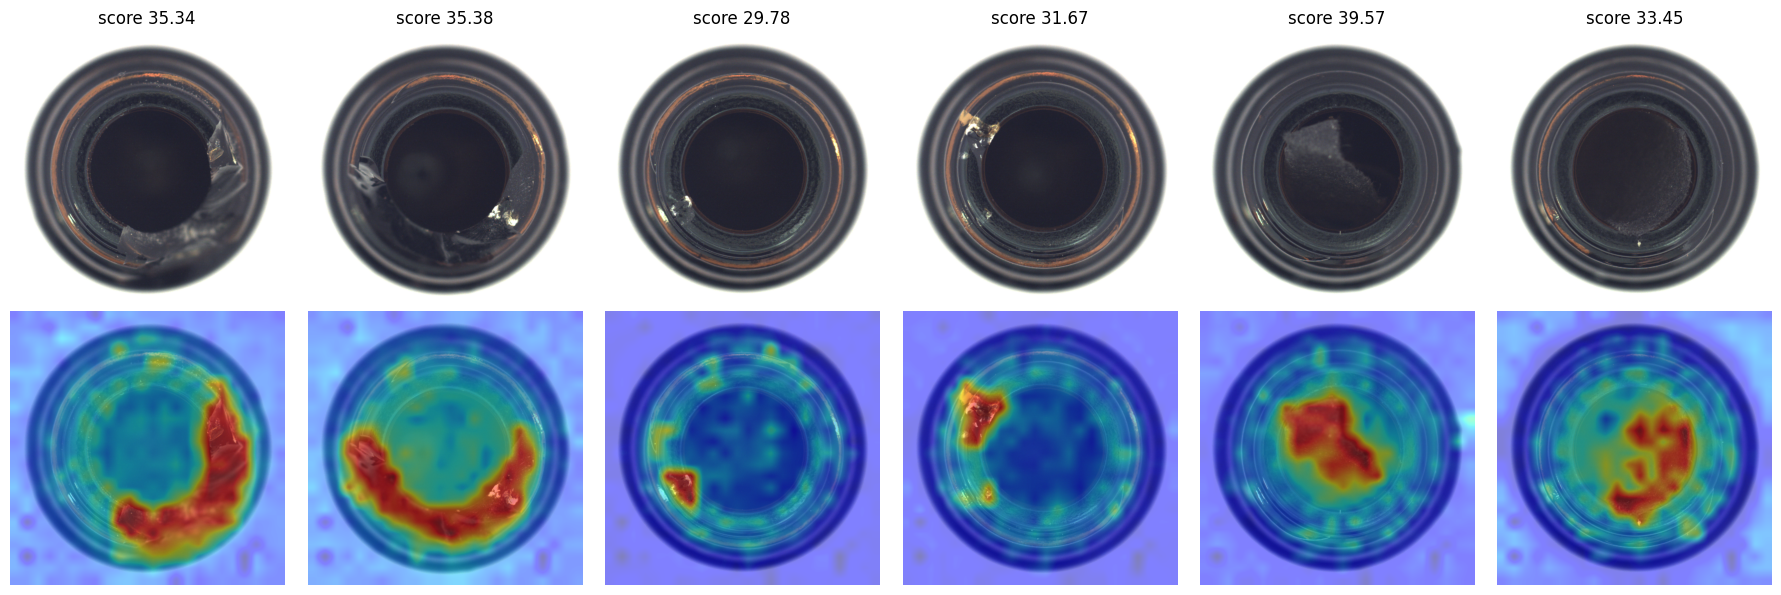

In [10]:
import matplotlib.pyplot as plt
paths = [p for d in ["broken_large","broken_small","contamination"]
         for p in sorted(glob.glob(f"{CAT}/test/{d}/*.png"))[:2]]
fig, ax = plt.subplots(2, len(paths), figsize=(3*len(paths), 6))
for i, p in enumerate(paths):
    img = Image.open(p).convert("RGB"); s, amap = score(img)
    ax[0,i].imshow(img); ax[0,i].axis("off"); ax[0,i].set_title(f"score {s:.2f}")
    ax[1,i].imshow(img); ax[1,i].imshow(amap, cmap="jet", alpha=0.5); ax[1,i].axis("off")
plt.tight_layout(); plt.savefig("results.png", dpi=120); plt.show()

Cell 4: Visualize heatmaps (put these in your portfolio)

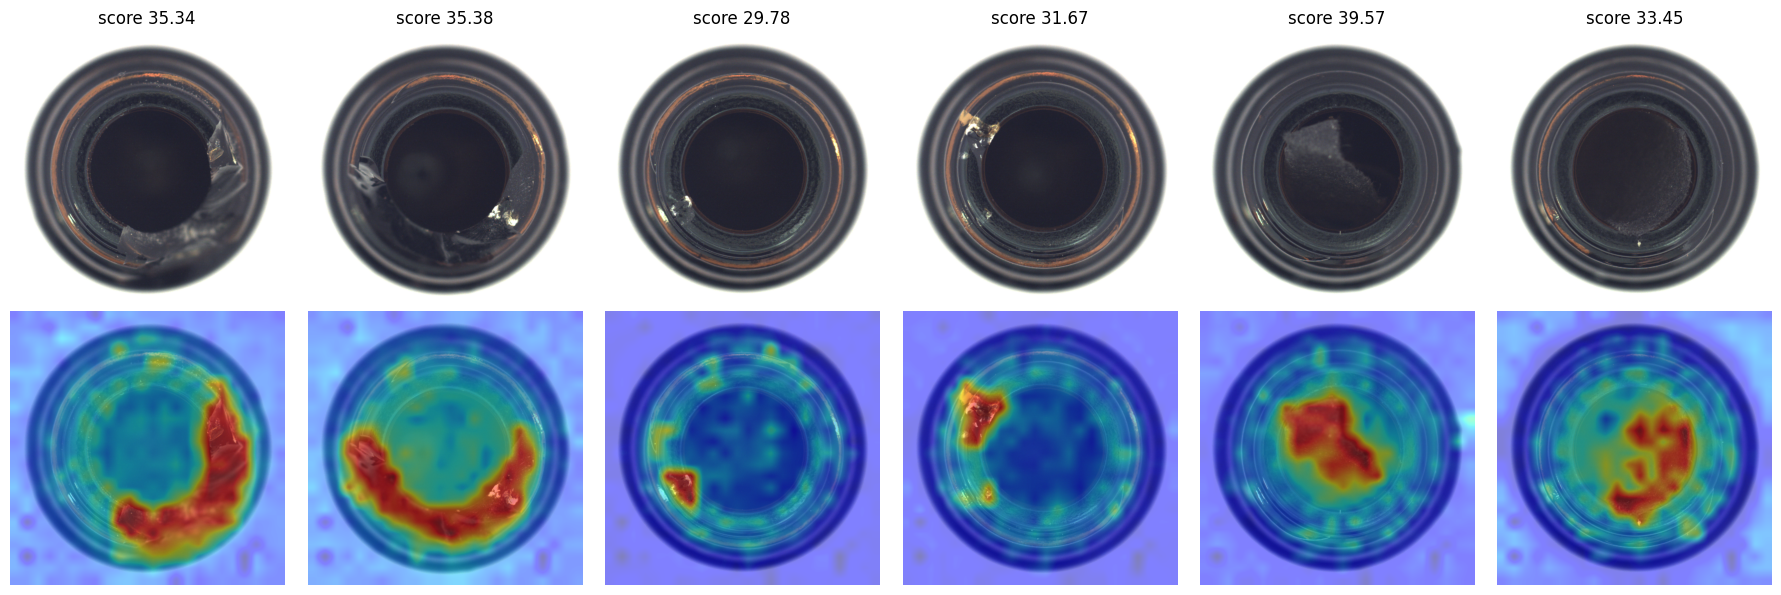

In [11]:
import matplotlib.pyplot as plt
paths = [p for d in ["broken_large","broken_small","contamination"]
         for p in sorted(glob.glob(f"{CAT}/test/{d}/*.png"))[:2]]
fig, ax = plt.subplots(2, len(paths), figsize=(3*len(paths), 6))
for i, p in enumerate(paths):
    img = Image.open(p).convert("RGB"); s, amap = score(img)
    ax[0,i].imshow(img); ax[0,i].axis("off"); ax[0,i].set_title(f"score {s:.2f}")
    ax[1,i].imshow(img); ax[1,i].imshow(amap, cmap="jet", alpha=0.5); ax[1,i].axis("off")
plt.tight_layout(); plt.savefig("results.png", dpi=120); plt.show()

Cell 5: Save the model

In [13]:
torch.save({"bank": bank.cpu(), "thr": thr, "size": SIZE}, "patchcore_dino.pt")

Cell 6: FastAPI endpoint

In [14]:
%%writefile app.py
import io, base64, numpy as np, torch, torch.nn.functional as F
from PIL import Image
import torchvision.transforms as T
from scipy.ndimage import gaussian_filter
from fastapi import FastAPI, UploadFile, File
import matplotlib; matplotlib.use("Agg")
from matplotlib import cm

device = "cuda" if torch.cuda.is_available() else "cpu"
ck = torch.load("patchcore_dino.pt")
bank, thr, SIZE = ck["bank"].to(device), ck["thr"], ck["size"]
G = SIZE // 14
model = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14").to(device).eval()
tf = T.Compose([T.Resize((SIZE,SIZE)), T.ToTensor(),
                T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
app = FastAPI(title="Product Defect Detector (DINOv2 + PatchCore)")

@app.post("/predict")
@torch.no_grad()
async def predict(file: UploadFile = File(...)):
    img = Image.open(io.BytesIO(await file.read())).convert("RGB")
    f = model.forward_features(tf(img).unsqueeze(0).to(device))["x_norm_patchtokens"][0]
    d = torch.cdist(f, bank).min(dim=1).values.reshape(1,1,G,G)
    amap = F.interpolate(d, size=img.size[::-1], mode="bilinear")[0,0].cpu().numpy()
    amap = gaussian_filter(amap, 4)
    s = float(amap.max())
    norm = np.clip(amap / (thr * 2), 0, 1)
    heat = (cm.jet(norm)[..., :3] * 255).astype(np.uint8)
    over = (0.5*np.array(img) + 0.5*heat).astype(np.uint8)
    buf = io.BytesIO(); Image.fromarray(over).save(buf, "PNG")
    return {"anomaly_score": s, "threshold": thr, "is_defect": s > thr,
            "heatmap_png_base64": base64.b64encode(buf.getvalue()).decode()}

@app.get("/health")
def health(): return {"status": "ok"}

Writing app.py


In [16]:
s = open("app.py").read()
s = s.replace("@torch.no_grad()\n", "")
s = s.replace('device = "cuda"', 'torch.set_grad_enabled(False)\ndevice = "cuda"', 1)
open("app.py", "w").write(s)
print(s[:700])

import io, base64, numpy as np, torch, torch.nn.functional as F
from PIL import Image
import torchvision.transforms as T
from scipy.ndimage import gaussian_filter
from fastapi import FastAPI, UploadFile, File
import matplotlib; matplotlib.use("Agg")
from matplotlib import cm

torch.set_grad_enabled(False)
device = "cuda" if torch.cuda.is_available() else "cpu"
ck = torch.load("patchcore_dino.pt")
bank, thr, SIZE = ck["bank"].to(device), ck["thr"], ck["size"]
G = SIZE // 14
model = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14").to(device).eval()
tf = T.Compose([T.Resize((SIZE,SIZE)), T.ToTensor(),
                T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
app = FastAPI


Cell 7: Run the API and test it

In [21]:
!pkill -f uvicorn
import subprocess, time, requests, glob, base64

log = open("server.log", "w")
subprocess.Popen(["uvicorn", "app:app", "--port", "8000"], stdout=log, stderr=log)

ready = False
for _ in range(60):
    try:
        if requests.get("http://127.0.0.1:8000/health").ok:
            ready = True; break
    except Exception:
        time.sleep(2)
print("Server ready:", ready)
if not ready:
    print(open("server.log").read()[-2000:])
else:
    p = sorted(glob.glob("mvtec/bottle/test/broken_large/*.png"))[0]
    resp = requests.post("http://127.0.0.1:8000/predict", files={"file": open(p, "rb")})
    print("Status:", resp.status_code)
    if resp.ok:
        r = resp.json()
        print("score:", r["anomaly_score"], "| threshold:", r["threshold"], "| defect:", r["is_defect"])
        open("api_result.png", "wb").write(base64.b64decode(r["heatmap_png_base64"]))
    else:
        print(resp.text[:500]); print(open("server.log").read()[-2000:])

Server ready: True
Status: 200
score: 35.34354019165039 | threshold: 26.42687225341797 | defect: True


In [20]:
s = open("app.py").read()
s = s.replace("np.clip(amap / (thr * 2), 0, 1)",
              "np.clip((amap - thr * 0.6) / (thr * 0.9), 0, 1)")
open("app.py", "w").write(s)

1641

Cell 8: Download your deliverables

In [23]:
from google.colab import files
for f in ["app.py", "patchcore_dino.pt", "results.png", "api_result.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>